# Hand Gesture Recognition: training notebook

In this notebook we will: download a HaGRID sample, crop the hands, fine-tune a pretrained **MobileNetV3**, evaluate it, and save `gesture_model.pt` for the live webcam app (`app.py`).

**Before you start**
1. Colab menu: *Runtime > Change runtime type > T4 GPU*.
2. Kaggle account: *Settings > API > Create New Token* downloads `kaggle.json` (you'll upload it in Step 2).

## Step 1: Check the GPU
Training on a GPU is 10-30x faster than on a CPU.

In [2]:
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

Using: cuda


## Step 2: Download the dataset
We use a ~31k-image, 384p sample of **HaGRID** (RGB webcam-style photos, many different people and backgrounds).
Check the dataset's license on its Kaggle page before using it beyond learning.

In [3]:
from google.colab import files
files.upload()   # pick your kaggle.json
!mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d innominate817/hagrid-sample-30k-384p -p /content/hagrid --unzip

cp: cannot stat 'kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/innominate817/hagrid-sample-30k-384p
License(s): CC-BY-SA-4.0
100% 823M/823M [00:06<00:00, 139MB/s]



In [4]:
from pathlib import Path
ROOT = Path("/content/hagrid")
ANN_DIR = next(ROOT.rglob("ann_train_val"))   # JSON annotations (hand boxes + labels)
IMG_DIR = next(ROOT.rglob("hagrid_30k"))      # images, one folder per gesture
print(ANN_DIR)
print(IMG_DIR)
print(sorted(p.name for p in IMG_DIR.iterdir()))

/content/hagrid/hagrid-sample-30k-384p/ann_train_val
/content/hagrid/hagrid-sample-30k-384p/hagrid_30k
['train_val_call', 'train_val_dislike', 'train_val_fist', 'train_val_four', 'train_val_like', 'train_val_mute', 'train_val_ok', 'train_val_one', 'train_val_palm', 'train_val_peace', 'train_val_peace_inverted', 'train_val_rock', 'train_val_stop', 'train_val_stop_inverted', 'train_val_three', 'train_val_three2', 'train_val_two_up', 'train_val_two_up_inverted']


## Step 3: Crop the hands and split by person
Why crop? At webcam time we will find the hand first and give the model only that crop, so we train the same way.

Why split by person? Photos of the same person look alike. If the same person is in both train and test, accuracy looks fake-high. We use each image's `user_id` so a person lands in only one split (about 70% train / 15% val / 15% test).

We can edit `CLASSES` to choose gestures. Start with a few distinct ones.

In [5]:
import json, hashlib
from PIL import Image

CLASSES = ["call", "dislike", "fist", "like", "ok", "one", "palm", "peace", "rock", "stop"]
PAD = 0.25                  # margin around the hand (fraction of its size). Keep the same in app.py
OUT = Path("/content/crops")

def split_of(user_id):
    h = int(hashlib.md5(user_id.encode()).hexdigest(), 16) % 100
    return "train" if h < 70 else "val" if h < 85 else "test"

def square_crop(img, box, pad=PAD):
    W, H = img.size
    x, y, w, h = box[0] * W, box[1] * H, box[2] * W, box[3] * H   # boxes are fractions of image size
    cx, cy = x + w / 2, y + h / 2
    side = max(w, h) * (1 + 2 * pad)
    return img.crop((int(cx - side / 2), int(cy - side / 2), int(cx + side / 2), int(cy + side / 2)))

counts = {"train": 0, "val": 0, "test": 0}
for g in CLASSES:
    ann = json.load(open(ANN_DIR / f"{g}.json"))
    folder = IMG_DIR / f"train_val_{g}"
    for img_id, a in ann.items():
        path = folder / f"{img_id}.jpg"
        if not path.exists():
            continue
        for box, label in zip(a["bboxes"], a["labels"]):
            if label != g:          # skip the extra "no_gesture" hand
                continue
            split = split_of(a["user_id"])
            dest = OUT / split / g
            dest.mkdir(parents=True, exist_ok=True)
            crop = square_crop(Image.open(path).convert("RGB"), box).resize((224, 224))
            crop.save(dest / f"{img_id}.jpg", quality=95)
            counts[split] += 1
            break
print(counts)

{'train': 12558, 'val': 2503, 'test': 2502}


CHOOSING RANDOM CROPPED IMAGES FOR PPT

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

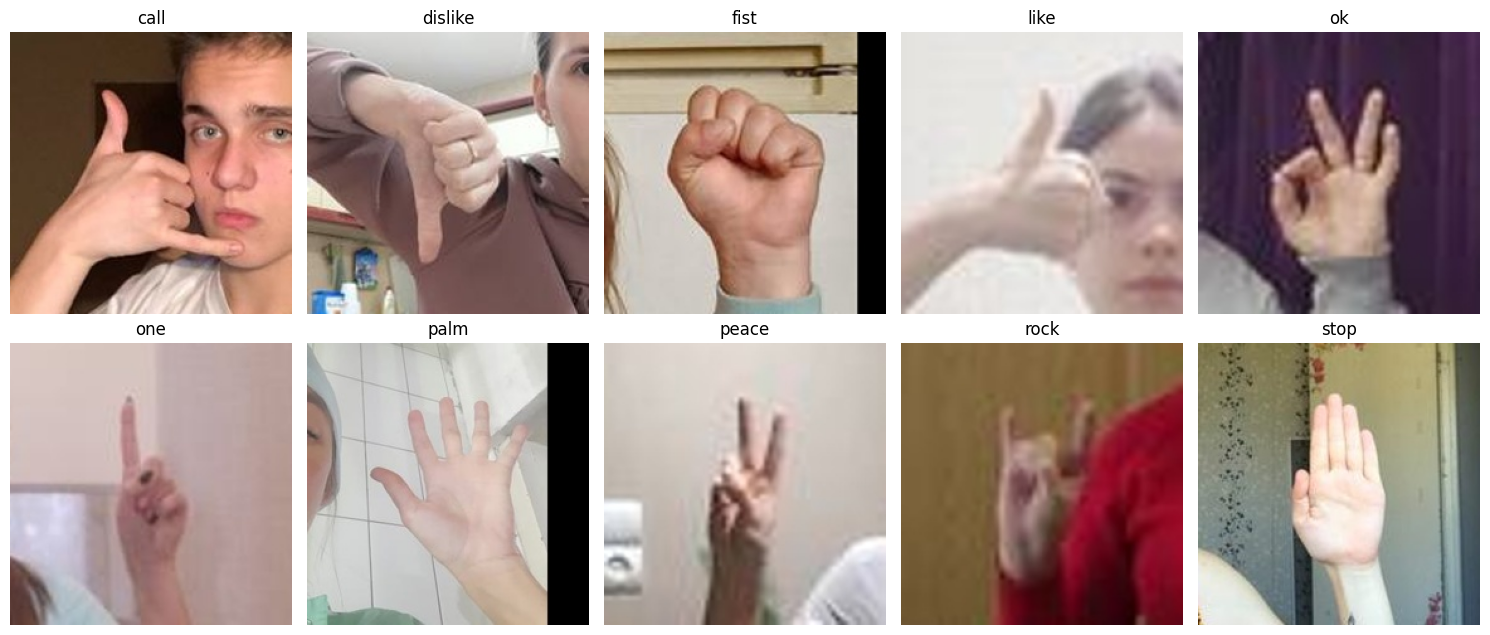

In [6]:
import random
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(2, 5, figsize=(15, 6.5))
for ax, g in zip(axes.flat, CLASSES):
    f = random.choice(list((OUT / "test" / g).glob("*.jpg")))
    ax.imshow(Image.open(f)); ax.set_title(g); ax.axis("off")
plt.tight_layout()
plt.savefig("gesture_samples.png", dpi=200)
files.download("gesture_samples.png")

## Step 4: Load the data (with augmentation)
Augmentation randomly rotates, zooms, flips, and changes colors during training so the model copes with real-world variation. Validation/test images are only resized.

Horizontal flips are fine here because HaGRID has left and right hands. Remove the flip if you add a gesture where left vs right matters.

In [6]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]   # ImageNet stats the pretrained model expects

train_tfm = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.75, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(0.3, 0.3, 0.3, 0.05),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
eval_tfm = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

train_ds = datasets.ImageFolder(OUT / "train", train_tfm)   # folder name = label
val_ds   = datasets.ImageFolder(OUT / "val", eval_tfm)
test_ds  = datasets.ImageFolder(OUT / "test", eval_tfm)
classes = train_ds.classes
print(classes, len(train_ds), len(val_ds), len(test_ds))

train_dl = DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=2)
val_dl   = DataLoader(val_ds, batch_size=64, num_workers=2)
test_dl  = DataLoader(test_ds, batch_size=64, num_workers=2)

['call', 'dislike', 'fist', 'like', 'ok', 'one', 'palm', 'peace', 'rock', 'stop'] 12558 2503 2502


## Step 5: Load the pretrained model
`weights="DEFAULT"` downloads MobileNetV3 already trained on ImageNet (1.2M images). It already understands edges, shapes and textures. We only replace its last layer so it outputs *our* gestures.

In [7]:
import torch.nn as nn
from torchvision import models

model = models.mobilenet_v3_large(weights="DEFAULT")
model.classifier[3] = nn.Linear(model.classifier[3].in_features, len(classes))
model = model.to(device)

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 156MB/s]


## Step 6: Fine-tune in two phases
- **Phase 1:** freeze the pretrained part (`features`) and train only the new last layers. Quick and stable.
- **Phase 2:** unfreeze everything and train gently (small learning rate) so the model adapts to hands.

If `train_acc` keeps rising while `val_acc` stalls, the model is overfitting.

In [8]:
criterion = nn.CrossEntropyLoss()

def run_epoch(loader, optimizer=None):
    train = optimizer is not None
    model.train(train)
    total = correct = loss_sum = 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            loss_sum += loss.item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
            total += len(y)
    return loss_sum / total, correct / total

best_acc = 0.0
def fit(epochs, optimizer):
    global best_acc
    for epoch in range(1, epochs + 1):
        tr_loss, tr_acc = run_epoch(train_dl, optimizer)
        va_loss, va_acc = run_epoch(val_dl)
        print(f"epoch {epoch}: train_acc {tr_acc:.3f}  val_acc {va_acc:.3f}  val_loss {va_loss:.3f}")
        if va_acc > best_acc:                       # keep the best version
            best_acc = va_acc
            torch.save(model.state_dict(), "best.pt")

# Phase 1: only the new head learns
for p in model.features.parameters():
    p.requires_grad = False
opt1 = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=1e-3)
fit(3, opt1)

# Phase 2: everything learns, gently
for p in model.parameters():
    p.requires_grad = True
opt2 = torch.optim.Adam(model.parameters(), lr=1e-4)
fit(8, opt2)

epoch 1: train_acc 0.609  val_acc 0.719  val_loss 0.799
epoch 2: train_acc 0.705  val_acc 0.745  val_loss 0.723
epoch 3: train_acc 0.729  val_acc 0.759  val_loss 0.700
epoch 1: train_acc 0.916  val_acc 0.959  val_loss 0.117
epoch 2: train_acc 0.969  val_acc 0.968  val_loss 0.092
epoch 3: train_acc 0.981  val_acc 0.980  val_loss 0.056
epoch 4: train_acc 0.985  val_acc 0.978  val_loss 0.070
epoch 5: train_acc 0.991  val_acc 0.984  val_loss 0.050
epoch 6: train_acc 0.991  val_acc 0.986  val_loss 0.045
epoch 7: train_acc 0.994  val_acc 0.985  val_loss 0.047
epoch 8: train_acc 0.994  val_acc 0.985  val_loss 0.049


## Step 7: Test on people the model has never seen
The confusion matrix shows which gestures get mixed up (rows = true, columns = predicted).

Test accuracy: 0.9904076738609112
              precision    recall  f1-score   support

        call       0.99      1.00      0.99       253
     dislike       1.00      1.00      1.00       259
        fist       1.00      1.00      1.00       235
        like       1.00      0.99      0.99       243
          ok       0.98      0.98      0.98       261
         one       0.98      0.99      0.99       246
        palm       0.99      0.98      0.99       277
       peace       0.98      0.99      0.99       255
        rock       0.99      1.00      0.99       239
        stop       0.99      0.98      0.98       234

    accuracy                           0.99      2502
   macro avg       0.99      0.99      0.99      2502
weighted avg       0.99      0.99      0.99      2502



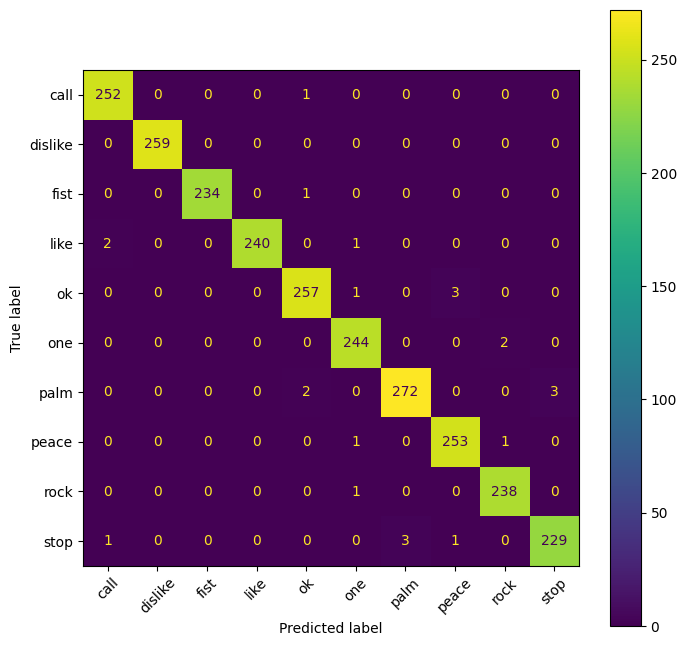

In [11]:
import numpy as np, matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

model.load_state_dict(torch.load("best.pt", map_location=device))
model.eval()
preds, truth = [], []
with torch.no_grad():
    for x, y in test_dl:
        preds += model(x.to(device)).argmax(1).cpu().tolist()
        truth += y.tolist()

print("Test accuracy:", np.mean(np.array(preds) == np.array(truth)))
print(classification_report(truth, preds, target_names=classes))
fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay(confusion_matrix(truth, preds), display_labels=classes).plot(ax=ax, xticks_rotation=45)
plt.show()

## Step 8: Save and download model
We download `gesture_model.pt` and put it in the same folder as `app.py` and `app_fixed_box.py` on your computer, then run `python app.py`.

In [12]:
torch.save({"state_dict": model.state_dict(), "classes": classes, "pad": PAD}, "gesture_model.pt")
files.download("gesture_model.pt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>